# Modelo 2 — Verificação de urgência

## 0. Contexto

No Acolhe+, o cidadão responde a perguntas sobre a queixa e recebe a indicação de
onde buscar atendimento, num fluxo inspirado no protocolo de Manchester. Este modelo
faz uma **verificação extra** antes de um resultado verde ou azul (não urgente): ele
estima se o caso parece **urgente**.

**Regra principal: o modelo só pode elevar.**
- Se o modelo indicar "urgente", a orientação sobe para atendimento de urgência.
- Se indicar "não urgente", vale o resultado do questionário.
- O modelo nunca rebaixa um caso que o questionário já classificou como urgente.

- **Base:** Emergency Service – Triage Application (Kaggle), com 1.267 adultos
  atendidos em duas emergências da Coreia do Sul (out/2016 a set/2017), classificados
  pela escala KTAS, de 5 níveis e parecida com a de Manchester.
- **Alvo:** coluna `KTAS_expert` (nível revisado por especialistas). Os níveis 1 a 3
  viram 1 (urgente) e os níveis 4 e 5 viram 0 (não urgente), o mesmo corte usado no
  sistema coreano.
- **Tipo de problema:** classificação binária.
- **Algoritmos comparados:** Regressão Logística, Árvore de Decisão e Random Forest.
- **Métrica principal:** recall da classe urgente, porque dizer "não urgente" para um
  caso urgente é o erro perigoso.

## Escopo do modelo

O Modelo 2 faz a verificação de urgência apenas para queixas de **dor**, incluindo
as associadas a **trauma**. Esse recorte foi definido por três motivos:

1. **Dor como discriminador geral do Protocolo de Manchester.** O protocolo organiza
   a classificação de risco em fluxogramas, um para cada queixa principal. A dor
   aparece como discriminador na maior parte deles e é graduada pela intensidade:
   quanto mais intensa, maior a prioridade de atendimento. Por isso, é o recorte
   mais abrangente para uma primeira versão do modelo.

2. **Relevância para o problema do Acolhe+.** A dor está entre as queixas mais
   frequentes nos serviços de urgência, e é nela que o cidadão costuma ter mais
   dificuldade para decidir sozinho se deve procurar a UBS, a UPA ou o SAMU.
   Orientar essa decisão ajuda a reduzir a procura pelo serviço errado e as filas.

3. **Segurança em um contexto de saúde.** Cobrir todos os fluxogramas do protocolo
   em um MVP aumentaria o risco de classificações incorretas, que têm impacto direto
   sobre o usuário. Um escopo menor permite validar o modelo com mais controle.

> **Importante:** o modelo tem caráter **orientativo, não diagnóstico**. Sinais de
> alarme sempre direcionam o usuário para o SAMU (192). A ampliação para outras
> queixas do Protocolo de Manchester fica prevista como evolução futura.

**Roteiro do notebook**
1. Instalação e importações
2. Leitura dos dados
3. Conhecendo a base
4. Limpeza e criação de variáveis
5. Seleção dos atributos
6. Análise exploratória
7. Separação treino / validação / teste
8. Pré-processamento e modelos
9. Treinamento
10. Escolha do modelo e do limiar
11. Avaliação no teste
12. Exemplo de previsão
13. Exportação
14. Conclusão

- **Fontes:** [base no Kaggle](https://www.kaggle.com/datasets/ilkeryildiz/emergency-service-triage-application)
  e [artigo original](https://journals.plos.org/plosone/article?id=10.1371/journal.pone.0216972).

## 1. Instalação e importações

A célula importa as ferramentas usadas no notebook e cria a pasta de trabalho, com
uma subpasta para cada tipo de arquivo da entrega (dados, modelos e resultados).
A semente (`SEED = 42`) fixa os sorteios para que os resultados se repitam a cada
execução.

Diferente do Modelo 1, aqui cada linha é um paciente diferente. Por isso a separação
usa o `train_test_split` com estratificação, sem precisar separar por paciente.

In [19]:
from pathlib import Path
import json
import shutil
import kagglehub

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display, Markdown
from google.colab import files

# Pré-processamento
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Modelos
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Separação dos dados
from sklearn.model_selection import train_test_split

# Métricas
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay
)

BASE = Path('/content/sus-urgencia')
for pasta in ['dados', 'modelos', 'resultados']:
    (BASE / pasta).mkdir(parents=True, exist_ok=True)

SEED = 42
print('Pasta de trabalho:', BASE)

Pasta de trabalho: /content/sus-urgencia


## 2. Leitura dos dados

A base é baixada direto do Kaggle com a biblioteca `kagglehub`, sem upload manual,
sempre na **versão 2**, para que uma atualização da base não mude os resultados.
Se a cópia do CSV já existir na pasta, ela é reaproveitada sem baixar de novo.
Uma cópia do CSV é salva em `dados/` para entrar no .zip da entrega. O arquivo usa
`;` como separador e uma codificação diferente de UTF-8, por isso a leitura informa
os dois. Os ajustes de valores (decimais com vírgula, textos no lugar de número)
ficam para a etapa de limpeza.

In [20]:
VERSAO_KAGGLE = 'ilkeryildiz/emergency-service-triage-application/versions/2'
caminho_csv = BASE / 'dados' / 'triagem_original.csv'

if not caminho_csv.exists():
    pasta_kaggle = Path(kagglehub.dataset_download(VERSAO_KAGGLE))
    print('Arquivos baixados:', [arquivo.name for arquivo in pasta_kaggle.glob('*')])
    arquivo_kaggle = next(pasta_kaggle.glob('*.csv'))
    shutil.copy(arquivo_kaggle, caminho_csv)
else:
    print('Usando a cópia local:', caminho_csv)

df_original = pd.read_csv(caminho_csv, sep=';', encoding='latin-1')
df_original.columns = df_original.columns.str.strip()

print('Linhas e colunas:', df_original.shape)
print('Colunas:', list(df_original.columns))
display(df_original.head())

Usando a cópia local: /content/sus-urgencia/dados/triagem_original.csv
Linhas e colunas: (1267, 24)
Colunas: ['Group', 'Sex', 'Age', 'Patients number per hour', 'Arrival mode', 'Injury', 'Chief_complain', 'Mental', 'Pain', 'NRS_pain', 'SBP', 'DBP', 'HR', 'RR', 'BT', 'Saturation', 'KTAS_RN', 'Diagnosis in ED', 'Disposition', 'KTAS_expert', 'Error_group', 'Length of stay_min', 'KTAS duration_min', 'mistriage']


,Group,Sex,Age,Patients number per hour,Arrival mode,Injury,Chief_complain,Mental,Pain,NRS_pain,...,BT,Saturation,KTAS_RN,Diagnosis in ED,Disposition,KTAS_expert,Error_group,Length of stay_min,KTAS duration_min,mistriage
0,2,2,71,3,3,2,right ocular pain,1,1,2,...,36.6,100,2,Corneal abrasion,1,4,2,86,"5,00",1
1,1,1,56,12,3,2,right forearm burn,1,1,2,...,36.5,NaN,4,"Burn of hand, firts degree dorsum",1,5,4,64,"3,95",1
2,2,1,68,8,2,2,"arm pain, Lt",1,1,2,...,36.6,98,4,"Fracture of surgical neck of humerus, closed",2,5,4,862,"1,00",1
3,1,2,71,8,1,1,ascites tapping,1,1,3,...,36.5,NaN,4,Alcoholic liver cirrhosis with ascites,1,5,6,108,"9,83",1
4,1,2,58,4,3,1,"distension, abd",1,1,3,...,36.5,NaN,4,Ascites,1,5,8,109,"6,60",1


## 3. Conhecendo a base

Antes de qualquer tratamento, verificamos os tipos das colunas, os valores ausentes,
a distribuição do alvo (`KTAS_expert`) e os códigos das colunas que podem entrar no
modelo. A coluna `NRS_pain` (nota da dor) também é conferida, porque pode trazer
textos no lugar de números quando a pessoa não tem dor.

In [21]:
df_original.info()

print('\nValores ausentes por coluna:')
display(df_original.isna().sum().to_frame('nulos'))

print('Distribuição do alvo (KTAS_expert):')
display(df_original['KTAS_expert'].value_counts().sort_index().to_frame('pacientes'))

print('Códigos das colunas candidatas:')
for coluna in ['Sex', 'Injury', 'Pain', 'Mental']:
    print(coluna, '→', df_original[coluna].value_counts().sort_index().to_dict())

print('\nIdades:')
display(df_original['Age'].describe().round(2))

nota_numerica = pd.to_numeric(df_original['NRS_pain'], errors='coerce')
print('Valores de NRS_pain que não são número:')
display(df_original.loc[nota_numerica.isna(), 'NRS_pain'].value_counts(dropna=False).to_frame('casos'))

print('Pain × nota da dor ausente ou em texto:')
display(pd.crosstab(df_original['Pain'], nota_numerica.isna(),
                    colnames=['nota ausente/texto']))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1267 entries, 0 to 1266
Data columns (total 24 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Group                     1267 non-null   int64 
 1   Sex                       1267 non-null   int64 
 2   Age                       1267 non-null   int64 
 3   Patients number per hour  1267 non-null   int64 
 4   Arrival mode              1267 non-null   int64 
 5   Injury                    1267 non-null   int64 
 6   Chief_complain            1267 non-null   object
 7   Mental                    1267 non-null   int64 
 8   Pain                      1267 non-null   int64 
 9   NRS_pain                  1267 non-null   object
 10  SBP                       1267 non-null   object
 11  DBP                       1267 non-null   object
 12  HR                        1267 non-null   object
 13  RR                        1267 non-null   object
 14  BT                      

,nulos
Group,0
Sex,0
Age,0
Patients number per hour,0
Arrival mode,0
Injury,0
Chief_complain,0
Mental,0
Pain,0
NRS_pain,0


Distribuição do alvo (KTAS_expert):


,pacientes
KTAS_expert,
1,26
2,220
3,487
4,459
5,75


Códigos das colunas candidatas:
Sex → {1: 606, 2: 661}
Injury → {1: 1023, 2: 244}
Pain → {0: 553, 1: 714}
Mental → {1: 1187, 2: 39, 3: 28, 4: 13}

Idades:


,Age
count,1267.00
mean,54.42
std,19.73
min,16.00
25%,37.00
50%,57.00
75%,71.00
max,96.00


Valores de NRS_pain que não são número:


,casos
NRS_pain,
#BOÞ!,556


Pain × nota da dor ausente ou em texto:


nota ausente/texto,False,True
Pain,,
0,0,553
1,711,3


### 3.1 Colunas que não entram no modelo

O modelo só usa o que o próprio cidadão consegue informar no app. As demais colunas
ficam de fora:

| Colunas | Motivo |
|---|---|
| `SBP`, `DBP`, `HR`, `RR`, `Saturation` | sinais vitais (pressão, frequências e saturação) que o cidadão não mede em casa |
| `BT` (temperatura) | nem todo cidadão tem termômetro; deixá-la de fora evita tratar campo vazio na API |
| `Diagnosis in ED`, `Disposition`, `Length of stay_min`, `KTAS duration_min`, `Error_group`, `mistriage` | só existem **depois** do atendimento; usá-las inflaria o resultado do modelo sem ter uso real (vazamento de dados) |
| `KTAS_RN` | é a classificação feita pela enfermagem, ou seja, outra resposta, e não um dado de entrada |
| `Group`, `Arrival mode`, `Patients number per hour` | descrevem o hospital e a chegada, e não o cidadão |
| `Chief_complain` | texto livre em inglês; no app, a queixa escolhida já define o questionário |

## 4. Limpeza e criação de variáveis

As colunas usadas são convertidas para nomes em português e para valores fáceis de
ler, no mesmo formato que o app vai enviar para a API:

| Coluna na base | Variável | Conversão |
|---|---|---|
| `Age` | `idade` | sem mudança |
| `Sex` | `sexo` | 1 → `F`, 2 → `M` |
| `Injury` | `trauma` | 1 (não) → 0, 2 (sim) → 1 |
| `Pain` | `dor` | 0 = não, 1 = sim |
| `NRS_pain` | `nota_dor` | número de 0 a 10; quem não tem dor recebe 0 |
| `Mental` | `alerta` | 1 (alerta) → 1; 2 a 4 (responde à voz, à dor ou não responde) → 0 |
| `KTAS_expert` | `urgente` | 1 a 3 → 1; 4 e 5 → 0 (alvo) |

O valor `#BOÞ!` em `NRS_pain` é um erro de fórmula do Excel que ficou no arquivo.
Ele aparece em todos os pacientes sem dor, que recebem nota 0. Três pacientes
marcados **com dor** também estão sem nota. Como não há como saber a intensidade
real, esses três registros são excluídos.

In [22]:
df = df_original.copy()

df['idade'] = df['Age']
df['sexo'] = df['Sex'].map({1: 'F', 2: 'M'})
df['trauma'] = df['Injury'].map({1: 0, 2: 1})
df['dor'] = df['Pain']
df['nota_dor'] = pd.to_numeric(df['NRS_pain'], errors='coerce')
df.loc[df['dor'] == 0, 'nota_dor'] = 0
df['alerta'] = (df['Mental'] == 1).astype(int)
df['urgente'] = (df['KTAS_expert'] <= 3).astype(int)

sem_nota = (df['dor'] == 1) & df['nota_dor'].isna()
print('Pacientes com dor e sem nota:', sem_nota.sum())

antes = len(df)
df = df[~sem_nota].reset_index(drop=True)
df['nota_dor'] = df['nota_dor'].astype(int)
print('Excluídos:', antes - len(df), '| Restantes:', len(df))

print('\nNotas de dor de quem tem dor:')
print(df.loc[df['dor'] == 1, 'nota_dor'].value_counts().sort_index().to_dict())
print('Notas fora de 0 a 10:', (~df['nota_dor'].between(0, 10)).sum())

display(df[['idade', 'sexo', 'trauma', 'dor', 'nota_dor', 'alerta', 'urgente']].head())

Pacientes com dor e sem nota: 3
Excluídos: 3 | Restantes: 1264

Notas de dor de quem tem dor:
{1: 2, 2: 38, 3: 278, 4: 141, 5: 136, 6: 70, 7: 33, 8: 9, 9: 1, 10: 3}
Notas fora de 0 a 10: 0


,idade,sexo,trauma,dor,nota_dor,alerta,urgente
0,71,M,1,1,2,1,0
1,56,F,1,1,2,1,0
2,68,F,1,1,2,1,0
3,71,M,0,1,3,1,0
4,58,M,0,1,3,1,0


## 5. Seleção dos atributos

Entram no modelo apenas informações que o próprio cidadão consegue informar no app:

| Atributo | Tipo | Pergunta equivalente no app |
|---|---|---|
| `idade` | numérico | perfil |
| `sexo` | categórico | perfil |
| `trauma` | numérico (0/1) | perguntado só na dor de cabeça; nas outras queixas, o app envia "não" |
| `dor` | numérico (0/1) | perguntado em todas as queixas, logo depois do perfil |
| `nota_dor` | numérico (0 a 10) | intensidade da dor, perguntada junto com a dor |
| `alerta` | numérico (0/1) | pergunta sobre o estado de consciência |

**Dor e nota da dor:** depois da limpeza, `dor` vale 1 exatamente quando a nota é
maior que 0. As duas são mantidas: `dor` marca o salto entre não ter e ter dor, e
`nota_dor` informa a intensidade.

**Fora do modelo:** as colunas da seção 3.1 (sinais vitais, temperatura, dados do
atendimento, classificação da enfermagem e dados do hospital).

In [23]:
NUMERICAS = ['idade', 'trauma', 'dor', 'nota_dor', 'alerta']
CATEGORICAS = ['sexo']
ATRIBUTOS = NUMERICAS + CATEGORICAS

display(pd.DataFrame({
    'tipo': df[ATRIBUTOS].dtypes.astype(str),
    'nulos': df[ATRIBUTOS].isna().sum()
}))

,tipo,nulos
idade,int64,0
trauma,int64,0
dor,int64,0
nota_dor,int64,0
alerta,int64,0
sexo,object,0


## 6. Análise exploratória

Os gráficos comparam a taxa de casos urgentes entre grupos. A linha tracejada marca a
taxa geral da base: barras acima dela indicam grupos com mais casos urgentes que a
média. O primeiro gráfico mostra os cinco níveis KTAS e o corte usado no alvo.

,idade,trauma,dor,nota_dor,alerta
count,1264.00,1264.00,1264.00,1264.00,1264.00
mean,54.36,0.19,0.56,2.31,0.94
std,19.70,0.39,0.50,2.30,0.24
min,16.00,0.00,0.00,0.00,0.00
25%,37.00,0.00,0.00,0.00,1.00
50%,57.00,0.00,1.00,3.00,1.00
75%,71.00,0.00,1.00,4.00,1.00
max,96.00,1.00,1.00,10.00,1.00


Taxa de casos urgentes: 57.75%
Acurácia de sempre prever "urgente": 57.75%


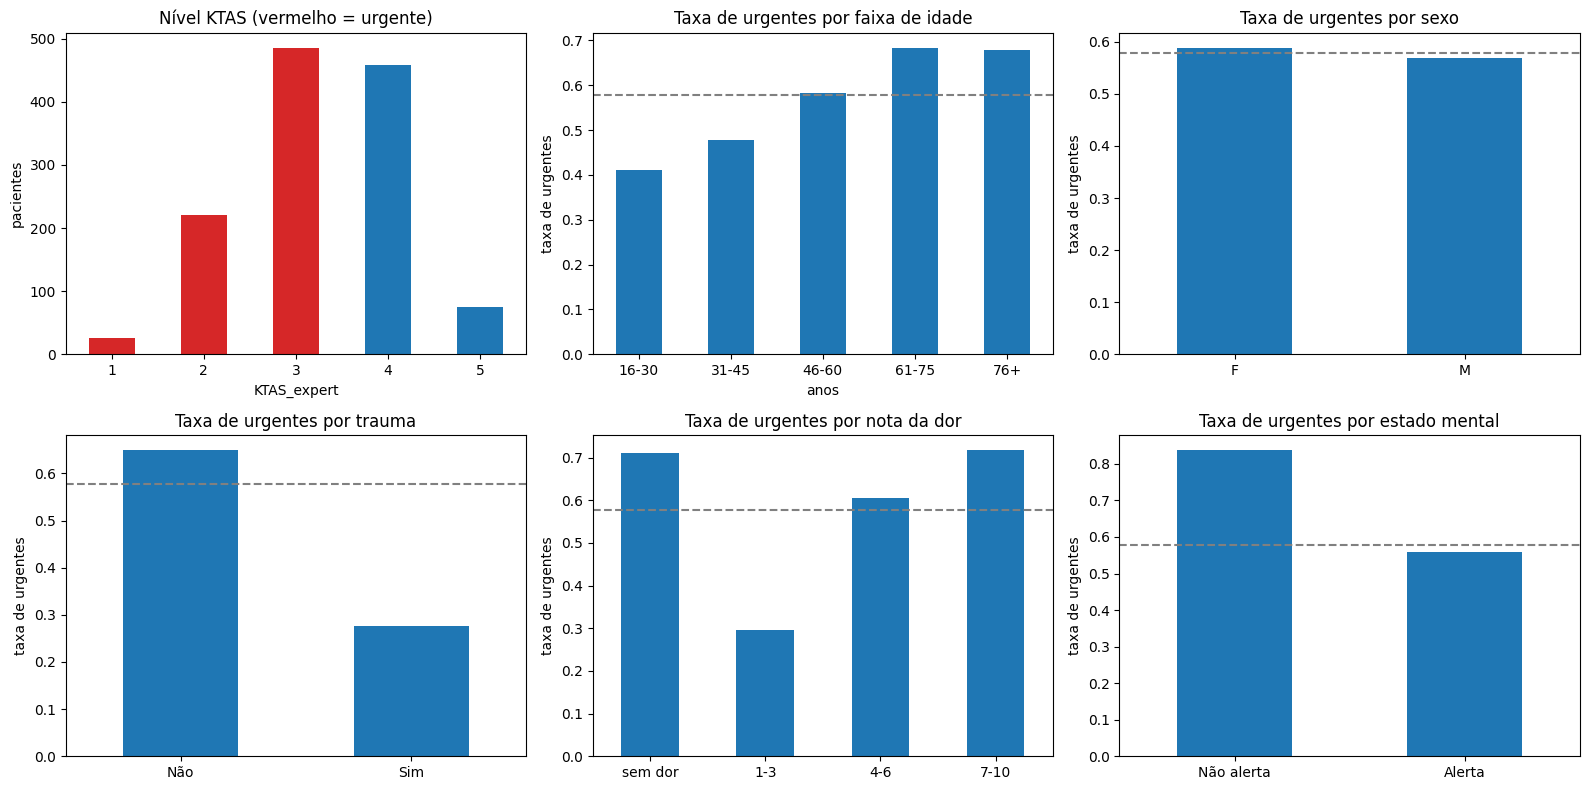

Taxas de urgentes por grupo:
idade → {'16-30': '41.1% (n=214)', '31-45': '47.8% (n=207)', '46-60': '58.2% (n=316)', '61-75': '68.3% (n=315)', '76+': '67.9% (n=212)'}
sexo → {'F': '58.8% (n=604)', 'M': '56.8% (n=660)'}
trauma → {'0': '64.9% (n=1021)', '1': '27.6% (n=243)'}
nota da dor → {'sem dor': '71.1% (n=553)', '1-3': '29.6% (n=318)', '4-6': '60.5% (n=347)', '7-10': '71.7% (n=46)'}
alerta → {'0': '83.8% (n=80)', '1': '56.0% (n=1184)'}


In [24]:
taxa_geral = df['urgente'].mean()

display(df[NUMERICAS].describe().round(2))
print('Taxa de casos urgentes:', f'{taxa_geral:.2%}')
print('Acurácia de sempre prever "urgente":', f'{taxa_geral:.2%}')

faixa_idade = pd.cut(df['idade'], [15, 30, 45, 60, 75, np.inf],
                     labels=['16-30', '31-45', '46-60', '61-75', '76+'])
faixa_dor = pd.cut(df['nota_dor'], [-1, 0, 3, 6, 10],
                   labels=['sem dor', '1-3', '4-6', '7-10'])

fig, ax = plt.subplots(2, 3, figsize=(16, 8))

niveis = df['KTAS_expert'].value_counts().sort_index()
cores = ['tab:red' if nivel <= 3 else 'tab:blue' for nivel in niveis.index]
niveis.plot.bar(ax=ax[0, 0], rot=0, color=cores)
ax[0, 0].set(title='Nível KTAS (vermelho = urgente)', xlabel='KTAS_expert', ylabel='pacientes')

df.groupby(faixa_idade, observed=True)['urgente'].mean().plot.bar(ax=ax[0, 1], rot=0)
ax[0, 1].set(title='Taxa de urgentes por faixa de idade', xlabel='anos')

df.groupby('sexo')['urgente'].mean().plot.bar(ax=ax[0, 2], rot=0)
ax[0, 2].set(title='Taxa de urgentes por sexo', xlabel='')

df.groupby('trauma')['urgente'].mean().plot.bar(ax=ax[1, 0], rot=0)
ax[1, 0].set(title='Taxa de urgentes por trauma', xlabel='')
ax[1, 0].set_xticklabels(['Não', 'Sim'])

df.groupby(faixa_dor, observed=True)['urgente'].mean().plot.bar(ax=ax[1, 1], rot=0)
ax[1, 1].set(title='Taxa de urgentes por nota da dor', xlabel='')

df.groupby('alerta')['urgente'].mean().plot.bar(ax=ax[1, 2], rot=0)
ax[1, 2].set(title='Taxa de urgentes por estado mental', xlabel='')
ax[1, 2].set_xticklabels(['Não alerta', 'Alerta'])

for eixo in ax.flat[1:]:
    eixo.axhline(taxa_geral, color='gray', linestyle='--')
    eixo.set_ylabel('taxa de urgentes')

plt.tight_layout()
plt.savefig(BASE / 'resultados' / 'exploracao.png', dpi=150)
plt.show()

print('Taxas de urgentes por grupo:')
for nome, grupo in [('idade', faixa_idade), ('sexo', df['sexo']), ('trauma', df['trauma']),
                    ('nota da dor', faixa_dor), ('alerta', df['alerta'])]:
    taxas = df.groupby(grupo, observed=True)['urgente'].agg(['mean', 'size'])
    print(nome, '→', {str(k): f"{v['mean']:.1%} (n={int(v['size'])})" for k, v in taxas.iterrows()})

In [25]:
por_dor = df.groupby(faixa_dor, observed=True)['urgente'].mean()
por_trauma = df.groupby('trauma')['urgente'].mean()
por_alerta = df.groupby('alerta')['urgente'].mean()
por_idade = df.groupby(faixa_idade, observed=True)['urgente'].mean()

display(Markdown(f"""
### Principais observações

1. **Estado mental.** Pacientes que não estavam alertas tiveram **{por_alerta[0]:.1%}**
   de casos urgentes, contra **{por_alerta[1]:.1%}** dos alertas. É o sinal mais forte
   entre as perguntas que o cidadão consegue responder.

2. **Dor.** Quem chegou **sem dor** teve **{por_dor['sem dor']:.1%}** de casos urgentes,
   acima da taxa geral. Essas pessoas costumam procurar a emergência por outras queixas,
   como falta de ar ou alteração neurológica, em que a dor não é o principal sinal. Entre
   quem tem dor, a taxa cresce com a intensidade: **{por_dor['1-3']:.1%}** com nota 1 a 3,
   **{por_dor['4-6']:.1%}** com 4 a 6 e **{por_dor['7-10']:.1%}** com 7 a 10. A dor, sozinha,
   não define a urgência, o que está de acordo com o artigo da base, que aponta a nota da
   dor como a principal causa de erro na triagem.

3. **Trauma e idade.** Casos com lesão ou trauma tiveram só **{por_trauma[1]:.1%}** de
   urgentes, contra **{por_trauma[0]:.1%}** sem trauma, porque na base a maior parte dos
   traumas é leve. Já a idade aumenta a taxa: **{por_idade['16-30']:.1%}** entre 16 e 30 anos
   e **{por_idade['61-75']:.1%}** entre 61 e 75.

Essas relações são **associações**, e não causas: ter dor não torna um caso menos
urgente. O modelo aprende padrões da base, e por isso a regra do Acolhe+ é que ele
**só pode elevar** a orientação, nunca rebaixá-la.

A base tem **{len(df)} pacientes**, com **{taxa_geral:.1%}** de casos urgentes. Um modelo
que sempre previsse "urgente" teria recall de 100% e acurácia de **{taxa_geral:.1%}**,
mas mandaria todos para a urgência. Por isso o modelo é avaliado pelo recall dos
urgentes junto com a precisão e a proporção de casos marcados como urgentes.
"""))


### Principais observações

1. **Estado mental.** Pacientes que não estavam alertas tiveram **83.8%**
   de casos urgentes, contra **56.0%** dos alertas. É o sinal mais forte
   entre as perguntas que o cidadão consegue responder.

2. **Dor.** Quem chegou **sem dor** teve **71.1%** de casos urgentes,
   acima da taxa geral. Essas pessoas costumam procurar a emergência por outras queixas,
   como falta de ar ou alteração neurológica, em que a dor não é o principal sinal. Entre
   quem tem dor, a taxa cresce com a intensidade: **29.6%** com nota 1 a 3,
   **60.5%** com 4 a 6 e **71.7%** com 7 a 10. A dor, sozinha,
   não define a urgência, o que está de acordo com o artigo da base, que aponta a nota da
   dor como a principal causa de erro na triagem.

3. **Trauma e idade.** Casos com lesão ou trauma tiveram só **27.6%** de
   urgentes, contra **64.9%** sem trauma, porque na base a maior parte dos
   traumas é leve. Já a idade aumenta a taxa: **41.1%** entre 16 e 30 anos
   e **68.3%** entre 61 e 75.

Essas relações são **associações**, e não causas: ter dor não torna um caso menos
urgente. O modelo aprende padrões da base, e por isso a regra do Acolhe+ é que ele
**só pode elevar** a orientação, nunca rebaixá-la.

A base tem **1264 pacientes**, com **57.8%** de casos urgentes. Um modelo
que sempre previsse "urgente" teria recall de 100% e acurácia de **57.8%**,
mas mandaria todos para a urgência. Por isso o modelo é avaliado pelo recall dos
urgentes junto com a precisão e a proporção de casos marcados como urgentes.


## 7. Separação treino / validação / teste

A base é dividida em três partes:

- **treino (60%)**: usado para o modelo aprender;
- **validação (20%)**: usada para comparar os algoritmos e escolher o limiar;
- **teste (20%)**: usado uma única vez, no fim, para medir o desempenho final.

Aqui cada linha é um paciente diferente, então não é preciso separar por paciente,
como no Modelo 1. A divisão usa o `train_test_split` duas vezes, com `stratify`, para
que cada parte mantenha a mesma proporção de casos urgentes (cerca de 58%).

Como a base é pequena, o teste tem cerca de 250 pacientes. Os resultados podem
variar mais do que no Modelo 1, e isso entra nas limitações.

In [26]:
X = df[ATRIBUTOS]
y = df['urgente']

X_resto, X_teste, y_resto, y_teste = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)
X_treino, X_validacao, y_treino, y_validacao = train_test_split(
    X_resto, y_resto, test_size=0.25, stratify=y_resto, random_state=SEED
)

for nome, rotulo in [('Treino', y_treino), ('Validação', y_validacao), ('Teste', y_teste)]:
    print(f'{nome}: {len(rotulo)} pacientes | urgentes: {rotulo.mean():.2%}')

Treino: 758 pacientes | urgentes: 57.78%
Validação: 253 pacientes | urgentes: 57.71%
Teste: 253 pacientes | urgentes: 57.71%


## 8. Pré-processamento e modelos

Cada modelo é um **Pipeline** com duas etapas, como no Modelo 1:
1. **Pré-processamento:** as variáveis numéricas são padronizadas (`StandardScaler`)
   e o sexo vira colunas 0/1 (`OneHotEncoder`). Uma categoria que não apareceu no
   treino é ignorada, sem gerar erro.
2. **Classificador:** um dos três algoritmos comparados.

Como o pré-processamento fica dentro do Pipeline, ele é salvo junto com o modelo e a
API recebe os dados no formato original.

| Algoritmo | Por que testar |
|---|---|
| Regressão Logística | modelo simples e interpretável, usado como referência |
| Árvore de Decisão | capta regras do tipo "se não está alerta..." ou "se tem dor com nota baixa..." |
| Random Forest | combina várias árvores e costuma errar menos que uma árvore só |

Os três usam `class_weight='balanced'`, que dá o mesmo peso às duas classes. Aqui o
desbalanceamento é leve (58% × 42%), mas a opção mantém o padrão do Modelo 1.

**Base pequena:** com cerca de 760 pacientes no treino, as árvores são limitadas em
profundidade (`max_depth`) e em tamanho mínimo das folhas (`min_samples_leaf`), para
não decorarem os exemplos do treino (sobreajuste).

In [27]:
def criar_preprocessamento(numericas, categoricas):
    return ColumnTransformer([
        ('numericas', StandardScaler(), numericas),
        ('categoricas', OneHotEncoder(handle_unknown='ignore'), categoricas)
    ])


def criar_modelos(numericas, categoricas):
    return {
        'Regressão Logística': Pipeline([
            ('preprocessamento', criar_preprocessamento(numericas, categoricas)),
            ('classificador', LogisticRegression(
                max_iter=2000, class_weight='balanced', random_state=SEED))
        ]),
        'Árvore de Decisão': Pipeline([
            ('preprocessamento', criar_preprocessamento(numericas, categoricas)),
            ('classificador', DecisionTreeClassifier(
                max_depth=4, min_samples_leaf=20,
                class_weight='balanced', random_state=SEED))
        ]),
        'Random Forest': Pipeline([
            ('preprocessamento', criar_preprocessamento(numericas, categoricas)),
            ('classificador', RandomForestClassifier(
                n_estimators=200, max_depth=5, min_samples_leaf=10,
                class_weight='balanced', n_jobs=-1, random_state=SEED))
        ])
    }

print('Função de modelos pronta.')

Função de modelos pronta.


## 9. Treinamento

Os três algoritmos são treinados com os mesmos atributos. A primeira comparação usa
a **ROC-AUC na validação**, que mede o quanto o modelo separa casos urgentes de não
urgentes, sem depender do limiar escolhido (0,5 = acaso; 1,0 = separação perfeita).
A ROC-AUC do treino também é mostrada: se ela for muito maior que a da validação, o
modelo está decorando o treino.

In [28]:
modelos = criar_modelos(NUMERICAS, CATEGORICAS)
linhas = []

for nome, modelo in modelos.items():
    print('Treinando:', nome)
    modelo.fit(X_treino, y_treino)
    linhas.append({
        'modelo': nome,
        'roc_auc_treino': roc_auc_score(y_treino, modelo.predict_proba(X_treino)[:, 1]),
        'roc_auc_validacao': roc_auc_score(y_validacao, modelo.predict_proba(X_validacao)[:, 1])
    })

comparacao_treino = pd.DataFrame(linhas)
comparacao_treino['diferenca'] = (
    comparacao_treino['roc_auc_treino'] - comparacao_treino['roc_auc_validacao']
)
print('\nROC-AUC no treino e na validação:')
display(comparacao_treino.round(4))

Treinando: Regressão Logística
Treinando: Árvore de Decisão
Treinando: Random Forest

ROC-AUC no treino e na validação:


,modelo,roc_auc_treino,roc_auc_validacao,diferenca
0,Regressão Logística,0.7852,0.7590,0.0262
1,Árvore de Decisão,0.8008,0.7842,0.0166
2,Random Forest,0.8328,0.7670,0.0658


## 10. Escolha do modelo e do limiar

**Limiar:** a pontuação vira "urgente" quando passa do limiar. Um limiar baixo deixa
passar menos casos urgentes (recall maior), mas marca mais casos como urgentes sem
necessidade (alarmes falsos). Um limiar alto erra menos nos alarmes, mas deixa passar
casos urgentes.

Regra adotada: para cada modelo, consideramos os limiares que mantêm o **recall dos
urgentes em pelo menos 90%** na validação e, entre eles, escolhemos o de **maior
precisão** (no empate, o maior limiar). O limiar fica baixo de propósito: aceitamos
mais alarmes falsos para não deixar passar casos urgentes. Um alarme falso leva o
cidadão a procurar a urgência sem necessidade; um caso urgente classificado como não
urgente pode atrasar um atendimento grave. Essa escolha sustenta a regra de que o
modelo **só pode elevar** a orientação.

Se nenhum limiar de um modelo atingir o recall mínimo, usamos o de maior recall
e registramos que a meta não foi alcançada.

A Árvore de Decisão só gera algumas pontuações diferentes (uma por folha). Por isso,
vários limiares seguidos podem dar exatamente o mesmo resultado, e um limiar maior
nem sempre significa menos casos marcados como urgentes.

**Modelo:** com o recall mínimo garantido, o modelo escolhido é o de **maior precisão**
na validação, ou seja, o que gera menos alarmes falsos. Em caso de empate, vale a maior
ROC-AUC.

**Observação:** com `class_weight='balanced'` e sem calibração, a saída do modelo é uma
**pontuação de risco** entre 0 e 1, e não uma porcentagem real. Uma pontuação de 0,70
indica um caso mais provavelmente urgente que 0,40, mas não significa "70% de chance
de ser urgente".

In [29]:
def avaliar(y_real, pontuacoes, limiar):
    previsto = (pontuacoes >= limiar).astype(int)
    return {
        'limiar': limiar,
        'casos_urgentes': previsto.mean(),
        'acuracia': accuracy_score(y_real, previsto),
        'precisao': precision_score(y_real, previsto, zero_division=0),
        'recall': recall_score(y_real, previsto, zero_division=0),
        'f1': f1_score(y_real, previsto, zero_division=0),
        'roc_auc': roc_auc_score(y_real, pontuacoes)
    }

In [30]:
RECALL_MINIMO = 0.90
limiares_testados = np.round(np.arange(0.10, 0.91, 0.05), 2)

tabelas_limiar = {}
resultados_validacao = []

for nome, modelo in modelos.items():
    pontuacoes = modelo.predict_proba(X_validacao)[:, 1]
    tabela = pd.DataFrame([
        avaliar(y_validacao, pontuacoes, limiar) for limiar in limiares_testados
    ])
    tabelas_limiar[nome] = tabela

    permitidos = tabela[tabela['recall'] >= RECALL_MINIMO]
    if permitidos.empty:
        print(f'{nome}: nenhum limiar atingiu recall de {RECALL_MINIMO:.0%}; usando o de maior recall.')
        melhor = tabela.sort_values(['recall', 'precisao'], ascending=False).iloc[0]
    else:
        melhor = permitidos.sort_values(['precisao', 'limiar'], ascending=False).iloc[0]
    resultados_validacao.append({'modelo': nome, **melhor.to_dict()})

comparacao_validacao = (
    pd.DataFrame(resultados_validacao)
    .sort_values(['precisao', 'roc_auc'], ascending=False)
    .reset_index(drop=True)
)
print(f'Limiar escolhido de cada modelo (recall >= {RECALL_MINIMO:.0%}, maior precisão) — validação:')
display(comparacao_validacao.round(4))

nome_escolhido = comparacao_validacao.loc[0, 'modelo']
modelo_final = modelos[nome_escolhido]
limiar_final = float(comparacao_validacao.loc[0, 'limiar'])

print('Modelo escolhido:', nome_escolhido)
print('Limiar escolhido:', limiar_final)
print(f'\nTodos os limiares testados — {nome_escolhido} (validação):')
display(tabelas_limiar[nome_escolhido].round(4))

Limiar escolhido de cada modelo (recall >= 90%, maior precisão) — validação:


,modelo,limiar,casos_urgentes,acuracia,precisao,recall,f1,roc_auc
0,Árvore de Decisão,0.30,0.7787,0.7115,0.6853,0.9247,0.7872,0.7842
1,Regressão Logística,0.30,0.7747,0.6917,0.6735,0.9041,0.7719,0.7590
2,Random Forest,0.35,0.7826,0.6917,0.6717,0.9110,0.7733,0.7670


Modelo escolhido: Árvore de Decisão
Limiar escolhido: 0.3

Todos os limiares testados — Árvore de Decisão (validação):


,limiar,casos_urgentes,acuracia,precisao,recall,f1,roc_auc
0,0.10,0.9605,0.6166,0.6008,1.0000,0.7506,0.7842
1,0.15,0.7787,0.7115,0.6853,0.9247,0.7872,0.7842
2,0.20,0.7787,0.7115,0.6853,0.9247,0.7872,0.7842
3,0.25,0.7787,0.7115,0.6853,0.9247,0.7872,0.7842
4,0.30,0.7787,0.7115,0.6853,0.9247,0.7872,0.7842
5,0.35,0.7708,0.7036,0.6821,0.9110,0.7801,0.7842
6,0.40,0.7036,0.7075,0.7022,0.8562,0.7716,0.7842
7,0.45,0.6126,0.7431,0.7613,0.8082,0.7841,0.7842
8,0.50,0.5929,0.7549,0.7800,0.8014,0.7905,0.7842
9,0.55,0.5929,0.7549,0.7800,0.8014,0.7905,0.7842


## 11. Avaliação no teste

Os três modelos são aplicados uma única vez ao conjunto de teste, cada um com o
limiar escolhido na validação. Como referência, a tabela inclui dois modelos simples:

- **sempre "urgente"**: não deixa passar nenhum caso urgente (recall de 100%), mas
  manda todos para a urgência;
- **sempre "não urgente"**: tem acurácia razoável, mas não encontra nenhum caso urgente.

- **Matriz de confusão:** mostra acertos e erros em cada classe. A célula destacada em
  vermelho é a dos **falsos negativos** (caso urgente classificado como não urgente),
  o erro mais perigoso para o Acolhe+.
- **Curva ROC:** mostra o desempenho em todos os limiares possíveis. Quanto mais a
  curva se afasta da diagonal (acaso), melhor o modelo separa as duas classes.

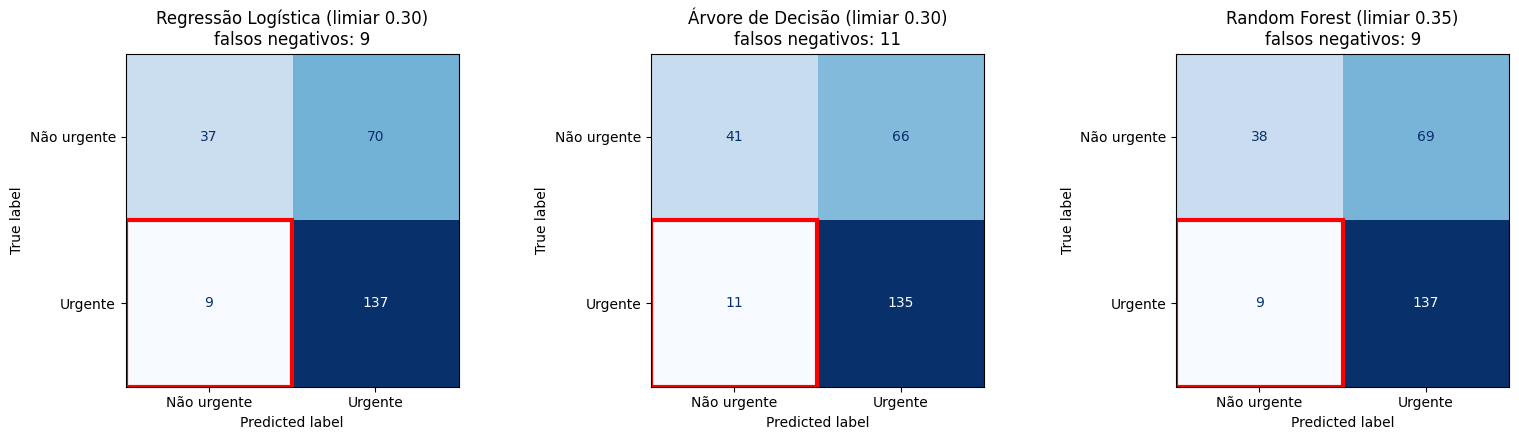

Resultados no teste:


,modelo,limiar,casos_urgentes,acuracia,precisao,recall,f1,roc_auc
0,Regressão Logística,0.30,0.8182,0.6877,0.6618,0.9384,0.7762,0.7127
1,Árvore de Decisão,0.30,0.7945,0.6957,0.6716,0.9247,0.7781,0.6877
2,Random Forest,0.35,0.8142,0.6917,0.6650,0.9384,0.7784,0.7250
3,"Sempre ""urgente""",NaN,1.0000,0.5771,0.5771,1.0000,0.7318,0.5000
4,"Sempre ""não urgente""",NaN,0.0000,0.4229,0.0000,0.0000,0.0000,0.5000


In [31]:
limiares_validacao = comparacao_validacao.set_index('modelo')['limiar']

resultados_teste = []
pontuacoes_teste = {}

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for eixo, (nome, modelo) in zip(ax, modelos.items()):
    pontuacoes = modelo.predict_proba(X_teste)[:, 1]
    limiar = float(limiares_validacao[nome])
    previsto = (pontuacoes >= limiar).astype(int)
    pontuacoes_teste[nome] = pontuacoes
    resultados_teste.append({'modelo': nome, **avaliar(y_teste, pontuacoes, limiar)})

    ConfusionMatrixDisplay.from_predictions(
        y_teste, previsto,
        labels=[0, 1], display_labels=['Não urgente', 'Urgente'],
        ax=eixo, colorbar=False, cmap='Blues'
    )
    # Destaque dos falsos negativos: real = urgente (linha 1), previsto = não urgente (coluna 0)
    eixo.add_patch(plt.Rectangle((-0.5, 0.5), 1, 1, fill=False, edgecolor='red', linewidth=3))
    falsos_negativos = int(((y_teste == 1) & (previsto == 0)).sum())
    eixo.set_title(f'{nome} (limiar {limiar:.2f})\nfalsos negativos: {falsos_negativos}')

plt.tight_layout()
plt.savefig(BASE / 'resultados' / 'matrizes_confusao.png', dpi=150)
plt.show()

taxa_teste = y_teste.mean()
referencias = [
    {'modelo': 'Sempre "urgente"', 'limiar': np.nan, 'casos_urgentes': 1.0,
     'acuracia': taxa_teste, 'precisao': taxa_teste, 'recall': 1.0,
     'f1': 2 * taxa_teste / (1 + taxa_teste), 'roc_auc': 0.5},
    {'modelo': 'Sempre "não urgente"', 'limiar': np.nan, 'casos_urgentes': 0.0,
     'acuracia': 1 - taxa_teste, 'precisao': 0.0, 'recall': 0.0,
     'f1': 0.0, 'roc_auc': 0.5}
]
comparacao_teste = pd.DataFrame(resultados_teste + referencias)
print('Resultados no teste:')
display(comparacao_teste.round(4))

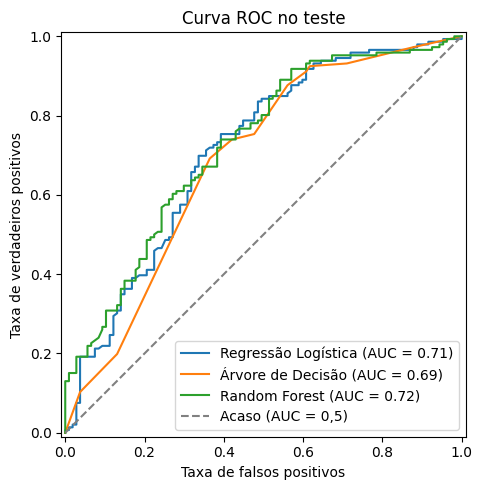

In [32]:
fig, ax = plt.subplots(figsize=(6, 5))
for nome, pontuacoes in pontuacoes_teste.items():
    RocCurveDisplay.from_predictions(y_teste, pontuacoes, name=nome, ax=ax)
ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Acaso (AUC = 0,5)')
ax.set(title='Curva ROC no teste',
       xlabel='Taxa de falsos positivos', ylabel='Taxa de verdadeiros positivos')
ax.legend()
plt.tight_layout()
plt.savefig(BASE / 'resultados' / 'curva_roc.png', dpi=150)
plt.show()

In [33]:
metricas = ['casos_urgentes', 'acuracia', 'precisao', 'recall', 'f1', 'roc_auc']
lado_a_lado = pd.DataFrame({
    'validação': comparacao_validacao.set_index('modelo').loc[nome_escolhido, metricas],
    'teste': comparacao_teste.set_index('modelo').loc[nome_escolhido, metricas]
}).astype(float)
lado_a_lado['diferença'] = lado_a_lado['teste'] - lado_a_lado['validação']

print('Modelo escolhido:', nome_escolhido)
display(lado_a_lado.round(4))

Modelo escolhido: Árvore de Decisão


,validação,teste,diferença
casos_urgentes,0.7787,0.7945,0.0158
acuracia,0.7115,0.6957,-0.0158
precisao,0.6853,0.6716,-0.0136
recall,0.9247,0.9247,0.0000
f1,0.7872,0.7781,-0.0091
roc_auc,0.7842,0.6877,-0.0965


## 12. Exemplo de previsão

As funções abaixo fazem o mesmo caminho que a API Flask vai fazer:

1. `validar_entrada` confere se todos os campos vieram e se os valores são válidos.
   Na API, a lista de erros vira uma resposta 400 com mensagem clara.
2. `verificar_urgencia` converte as respostas do cidadão para o formato do modelo,
   calcula a pontuação de risco e compara com o limiar.

Regras da entrada:
- `idade` entre 18 e 120 anos, a mesma regra do app: o Acolhe+ só faz a orientação
  para maiores de idade, e quem tem menos de 18 é orientado a procurar a UBS ou, em
  emergência, o SAMU (192). A base de treino começa aos 16 anos, então todas as
  idades aceitas estão dentro do que o modelo aprendeu;
- `sexo` igual a `F` ou `M`;
- `trauma`, `dor` e `alerta` como verdadeiro ou falso;
- `nota_dor` de 1 a 10 quando há dor; sem dor, a nota é sempre 0.

Regra do Acolhe+: a resposta só é usada para **elevar** a orientação. Se `urgente`
for verdadeiro, o cidadão é orientado a procurar atendimento de urgência; se for
falso, vale o resultado do questionário.

In [34]:
CAMPOS_OBRIGATORIOS = ['idade', 'sexo', 'trauma', 'dor', 'alerta']


def validar_entrada(dados):
    erros = []
    for campo in CAMPOS_OBRIGATORIOS:
        if campo not in dados or dados[campo] is None:
            erros.append(f'Campo obrigatório ausente: {campo}')
    if erros:
        return erros

    idade = dados['idade']
    if not isinstance(idade, int) or isinstance(idade, bool) or not 18 <= idade <= 120:
        erros.append('idade deve ser um número inteiro entre 18 e 120 '
                     '(menores de 18 devem procurar a UBS ou, em emergência, o SAMU 192)')

    if str(dados['sexo']).strip().upper() not in ['F', 'M']:
        erros.append('sexo deve ser "F" ou "M"')

    for campo in ['trauma', 'dor', 'alerta']:
        if not isinstance(dados[campo], bool):
            erros.append(f'{campo} deve ser true ou false')

    if dados['dor'] is True:
        nota = dados.get('nota_dor')
        if not isinstance(nota, int) or isinstance(nota, bool) or not 1 <= nota <= 10:
            erros.append('nota_dor deve ser um número inteiro de 1 a 10 quando dor = true')

    return erros


def verificar_urgencia(dados):
    entrada = {
        'idade': dados['idade'],
        'sexo': str(dados['sexo']).strip().upper(),
        'trauma': int(dados['trauma']),
        'dor': int(dados['dor']),
        'nota_dor': int(dados['nota_dor']) if dados['dor'] else 0,
        'alerta': int(dados['alerta'])
    }

    tabela = pd.DataFrame([entrada])[ATRIBUTOS]
    pontuacao = float(modelo_final.predict_proba(tabela)[0, 1])

    return {
        'urgente': pontuacao >= limiar_final,
        'pontuacao_risco': round(pontuacao, 4),
        'limiar': limiar_final
    }


exemplos = [
    {'idade': 25, 'sexo': 'M', 'trauma': True, 'dor': True, 'nota_dor': 3, 'alerta': True},
    {'idade': 78, 'sexo': 'F', 'trauma': False, 'dor': False, 'alerta': False},
    {'idade': 45, 'sexo': 'F', 'trauma': False, 'dor': True, 'nota_dor': 12}
]

for exemplo in exemplos:
    print('Entrada:', exemplo)
    erros = validar_entrada(exemplo)
    if erros:
        print('Erro 400:', erros)
    else:
        print('Saída:  ', json.dumps(verificar_urgencia(exemplo), ensure_ascii=False))
    print()

Entrada: {'idade': 25, 'sexo': 'M', 'trauma': True, 'dor': True, 'nota_dor': 3, 'alerta': True}
Saída:   {"urgente": false, "pontuacao_risco": 0.1487, "limiar": 0.3}

Entrada: {'idade': 78, 'sexo': 'F', 'trauma': False, 'dor': False, 'alerta': False}
Saída:   {"urgente": true, "pontuacao_risco": 0.7138, "limiar": 0.3}

Entrada: {'idade': 45, 'sexo': 'F', 'trauma': False, 'dor': True, 'nota_dor': 12}
Erro 400: ['Campo obrigatório ausente: alerta']



## 13. Exportação do modelo

O modelo escolhido é salvo com `joblib` em um pacote que reúne tudo o que a API
precisa: o Pipeline (pré-processamento + classificador), a lista de atributos, o
limiar, o recall mínimo usado na escolha e as métricas do teste.

As versões do scikit-learn, do NumPy, do pandas e do joblib também são registradas,
porque a API precisa usar as mesmas versões para carregar o arquivo (elas vão para o
`requirements.txt` da API). Ao final, o arquivo é carregado de novo e as pontuações
são comparadas com as do modelo em memória, para garantir que ele não está corrompido.

In [35]:
import sklearn
import importlib.metadata

pacote = {
    'modelo': modelo_final,
    'nome_modelo': nome_escolhido,
    'atributos': ATRIBUTOS,
    'limiar': limiar_final,
    'recall_minimo': RECALL_MINIMO,
    'metricas_teste': comparacao_teste.set_index('modelo').loc[nome_escolhido].to_dict(),
    'versao_sklearn': sklearn.__version__,
    'versoes': {nome: importlib.metadata.version(nome)
                for nome in ['scikit-learn', 'numpy', 'pandas', 'joblib']}
}

caminho_modelo = BASE / 'modelos' / 'modelo_urgencia.joblib'
joblib.dump(pacote, caminho_modelo)
print('Salvo:', caminho_modelo)
print('Tamanho:', round(caminho_modelo.stat().st_size / 1024, 2), 'KB')
print('Versão do scikit-learn:', sklearn.__version__)

carregado = joblib.load(caminho_modelo)
entrada_teste = X_teste.head(5)[carregado['atributos']]
np.testing.assert_allclose(
    modelo_final.predict_proba(entrada_teste)[:, 1],
    carregado['modelo'].predict_proba(entrada_teste)[:, 1]
)
assert carregado['limiar'] == limiar_final
print('Arquivo conferido: mesmas pontuações e mesmo limiar do modelo em memória.')
print('Versões:', carregado['versoes'])
print('\nTeste do arquivo salvo:')
print('Modelo:', carregado['nome_modelo'], '| limiar:', carregado['limiar'])
print('Pontuações de 5 pacientes do teste:',
      carregado['modelo'].predict_proba(entrada_teste)[:, 1].round(4))

files.download(str(caminho_modelo))
files.download(str(caminho_csv))

Salvo: /content/sus-urgencia/modelos/modelo_urgencia.joblib
Tamanho: 5.78 KB
Versão do scikit-learn: 1.6.1
Arquivo conferido: mesmas pontuações e mesmo limiar do modelo em memória.
Versões: {'scikit-learn': '1.6.1', 'numpy': '2.4.6', 'pandas': '2.2.3', 'joblib': '1.6.0'}

Teste do arquivo salvo:
Modelo: Árvore de Decisão | limiar: 0.3
Pontuações de 5 pacientes do teste: [0.7138 0.7138 0.1487 0.7138 0.045 ]


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 14. Conclusão

In [36]:
r = comparacao_teste.set_index('modelo').loc[nome_escolhido]
ref = comparacao_teste.set_index('modelo').loc['Sempre "urgente"']
v = comparacao_validacao.set_index('modelo').loc[nome_escolhido]

previsto_final = (pontuacoes_teste[nome_escolhido] >= limiar_final).astype(int)
falsos_negativos = int(((y_teste == 1) & (previsto_final == 0)).sum())
urgentes_teste = int(y_teste.sum())

display(Markdown(f"""
**Modelo escolhido:** {nome_escolhido}, com limiar de **{limiar_final:.2f}**, escolhido na
validação como o de maior precisão entre os limiares com recall dos urgentes de pelo
menos **{RECALL_MINIMO:.0%}**.

**Desempenho no teste:**
- recall de **{r['recall']:.1%}**: dos **{urgentes_teste}** casos urgentes do teste,
  **{falsos_negativos}** foram classificados como não urgentes (falsos negativos);
- precisão de **{r['precisao']:.1%}**: proporção dos casos marcados como urgentes que
  de fato eram urgentes;
- **{r['casos_urgentes']:.1%}** dos casos marcados como urgentes;
- ROC-AUC de **{r['roc_auc']:.3f}** (0,5 seria o acaso).

O modelo que sempre responde "urgente" tem recall de 100%, mas precisão de apenas
**{ref['precisao']:.1%}**, porque manda todos para a urgência. O modelo proposto mantém
quase todos os casos urgentes e reduz os alarmes falsos, o que é adequado ao uso no
Acolhe+: um alarme falso leva o cidadão à urgência sem necessidade, enquanto um caso
urgente não identificado pode atrasar um atendimento grave.

**Uso na solução:** o modelo é uma verificação extra antes de um resultado verde ou
azul do questionário, e **só pode elevar** a orientação. Ele nunca rebaixa um caso
que o questionário já classificou como urgente.

**Limitações:**
- a base é pequena ({len(df)} pacientes), e por isso os resultados variam entre a
  validação e o teste: a ROC-AUC caiu de **{v['roc_auc']:.3f}** para **{r['roc_auc']:.3f}**.
  A Árvore de Decisão gera poucas pontuações diferentes (uma por folha), o que deixa
  essa métrica mais instável. O modelo não foi trocado com base no teste, para que o
  teste continue sendo uma medida independente;
- os dados são de pacientes que já estavam em duas emergências da Coreia do Sul, com
  {taxa_geral:.0%} de casos urgentes. No Acolhe+, o modelo só avalia casos que o
  questionário classificou como não urgentes, então a proporção de casos elevados tende
  a ser menor, e o modelo deveria ser reavaliado com dados brasileiros;
- o modelo usa só o que o cidadão informa; sinais vitais, que ajudariam muito na
  classificação, ficaram de fora porque não são medidos em casa;
- os dados foram registrados por profissionais na triagem; no Acolhe+, quem responde
  é o próprio cidadão, que pode descrever os sintomas de outro jeito;
- a base não tem identificação dos pacientes, então não dá para conferir se a mesma
  pessoa aparece em mais de um atendimento;
- o modelo não define a cor de Manchester nem o destino; ele só indica se o caso
  deve ser elevado para urgência;
- a base tem apenas adultos, e a API segue a regra do app, que só faz a orientação a
  partir de 18 anos;
- a saída é uma pontuação de risco, e não uma probabilidade calibrada;
- antes de qualquer uso real, o modelo precisaria de validação com dados locais e de
  avaliação de profissionais de saúde.
"""))


**Modelo escolhido:** Árvore de Decisão, com limiar de **0.30**, escolhido na
validação como o de maior precisão entre os limiares com recall dos urgentes de pelo
menos **90%**.

**Desempenho no teste:**
- recall de **92.5%**: dos **146** casos urgentes do teste,
  **11** foram classificados como não urgentes (falsos negativos);
- precisão de **67.2%**: proporção dos casos marcados como urgentes que
  de fato eram urgentes;
- **79.4%** dos casos marcados como urgentes;
- ROC-AUC de **0.688** (0,5 seria o acaso).

O modelo que sempre responde "urgente" tem recall de 100%, mas precisão de apenas
**57.7%**, porque manda todos para a urgência. O modelo proposto mantém
quase todos os casos urgentes e reduz os alarmes falsos, o que é adequado ao uso no
Acolhe+: um alarme falso leva o cidadão à urgência sem necessidade, enquanto um caso
urgente não identificado pode atrasar um atendimento grave.

**Uso na solução:** o modelo é uma verificação extra antes de um resultado verde ou
azul do questionário, e **só pode elevar** a orientação. Ele nunca rebaixa um caso
que o questionário já classificou como urgente.

**Limitações:**
- a base é pequena (1264 pacientes), e por isso os resultados variam entre a
  validação e o teste: a ROC-AUC caiu de **0.784** para **0.688**.
  A Árvore de Decisão gera poucas pontuações diferentes (uma por folha), o que deixa
  essa métrica mais instável. O modelo não foi trocado com base no teste, para que o
  teste continue sendo uma medida independente;
- os dados são de pacientes que já estavam em duas emergências da Coreia do Sul, com
  58% de casos urgentes. No Acolhe+, o modelo só avalia casos que o
  questionário classificou como não urgentes, então a proporção de casos elevados tende
  a ser menor, e o modelo deveria ser reavaliado com dados brasileiros;
- o modelo usa só o que o cidadão informa; sinais vitais, que ajudariam muito na
  classificação, ficaram de fora porque não são medidos em casa;
- os dados foram registrados por profissionais na triagem; no Acolhe+, quem responde
  é o próprio cidadão, que pode descrever os sintomas de outro jeito;
- a base não tem identificação dos pacientes, então não dá para conferir se a mesma
  pessoa aparece em mais de um atendimento;
- o modelo não define a cor de Manchester nem o destino; ele só indica se o caso
  deve ser elevado para urgência;
- a base tem apenas adultos, e a API segue a regra do app, que só faz a orientação a
  partir de 18 anos;
- a saída é uma pontuação de risco, e não uma probabilidade calibrada;
- antes de qualquer uso real, o modelo precisaria de validação com dados locais e de
  avaliação de profissionais de saúde.
